In [6]:
import numpy as np
import matplotlib.pyplot as plt
import skimage as ski
from skimage import color

In [ ]:
def filtro_manual(image, kernel_size, filter_func):
    # define o tamanho do preenchimento baseado no tamanho do kernel
    pad = kernel_size // 2
    
    # aplica o zero-padding nas bordas para tratar os pixels extremos
    padded_img = np.pad(image, pad, mode='constant', constant_values=0)
    output = np.zeros_like(image, dtype=np.float64)
    for i in range(image.shape[0]):
        for j in range(image.shape[1]):
            # pega a vizinhança local
            window = padded_img[i:i+kernel_size, j:j+kernel_size]
            # aplica a função de agregação (média, mediana, etc)
            output[i, j] = filter_func(window)
    return np.clip(output, 0, 255).astype(np.uint8)

In [8]:
def filtro_media(image, kernel_size=3):
    return filtro_manual(image, kernel_size, np.mean)

def filtro_mediana(image, kernel_size=3):
    return filtro_manual(image, kernel_size, np.median)

def filtro_moda(image, kernel_size=3):
    def mode_func(window):
        # Retorna o valor que mais se repete na vizinhança
        valores, contagens = np.unique(window, return_counts=True)
        return valores[np.argmax(contagens)]
    return filtro_manual(image, kernel_size, mode_func)

def filtro_maxima(image, kernel_size=3):
    return filtro_manual(image, kernel_size, np.max)


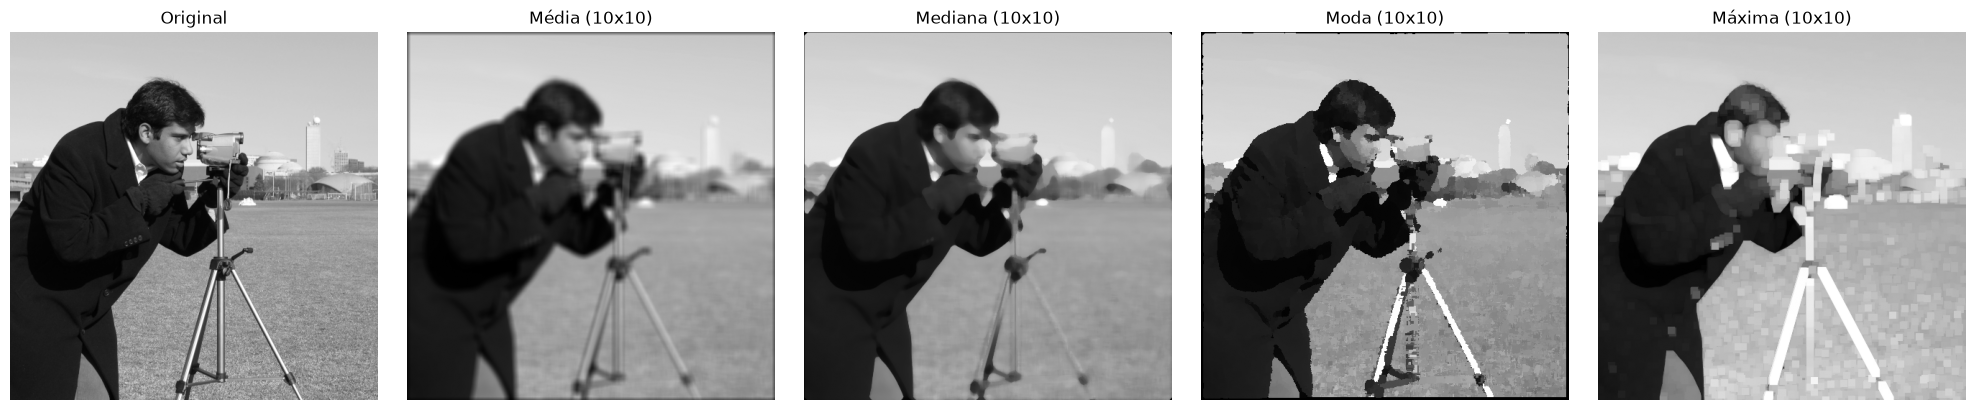

In [9]:
chamada = getattr(ski.data, 'camera')
img_original = chamada()

# aplica os filtros
k_size = 10
img_media = filtro_media(img_original, kernel_size=k_size)
img_mediana = filtro_mediana(img_original, kernel_size=k_size)
img_moda = filtro_moda(img_original, kernel_size=k_size)
img_maxima = filtro_maxima(img_original, kernel_size=k_size)

# plot
fig, axes = plt.subplots(1, 5, figsize=(20, 4))

axes[0].imshow(img_original, cmap='gray')
axes[0].set_title('Original')
axes[0].axis('off')

axes[1].imshow(img_media, cmap='gray')
axes[1].set_title(f'Média ({k_size}x{k_size})')
axes[1].axis('off')

axes[2].imshow(img_mediana, cmap='gray')
axes[2].set_title(f'Mediana ({k_size}x{k_size})')
axes[2].axis('off')

axes[3].imshow(img_moda, cmap='gray')
axes[3].set_title(f'Moda ({k_size}x{k_size})')
axes[3].axis('off')

axes[4].imshow(img_maxima, cmap='gray')
axes[4].set_title(f'Máxima ({k_size}x{k_size})')
axes[4].axis('off')

plt.tight_layout()
plt.show()